In [229]:
!pip install torch

In [230]:
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [231]:
if torch.cuda.is_available():
  device = "gpu"

else:
  device = "cpu"

In [232]:
device

'gpu'

In [233]:
df = pd.read_csv("06-study_hours_grades.csv")

In [234]:
df.head()

,study_hours,grade
0,3.745401,30.203939
1,9.507143,57.878452
2,7.319939,46.368401
3,5.986585,39.330717
4,1.560186,14.843888


In [235]:
df.shape

(50, 2)

In [236]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  50 non-null     float64
 1   grade        50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


In [237]:
df.describe()

,study_hours,grade
count,50.000000,50.000000
mean,4.459239,32.290305
std,2.888832,14.431931
min,0.205845,11.032281
25%,1.837670,21.062901
50%,4.360488,31.231858
75%,6.498549,41.683170
max,9.699099,60.573564


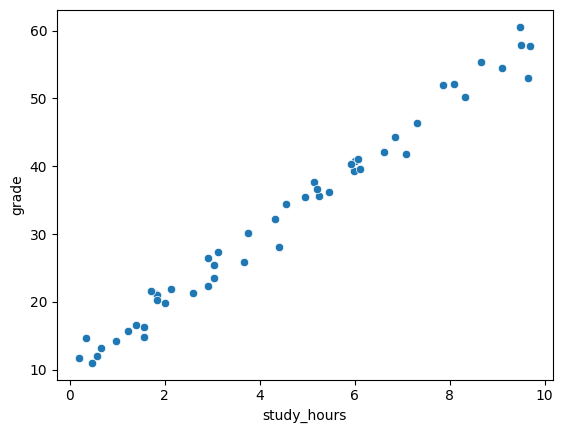

In [238]:
sns.scatterplot(data=df, x="study_hours",y="grade")
plt.show()

In [239]:
x = df["study_hours"]
y = df["grade"]

In [240]:
x = sm.add_constant(x)

In [241]:
x.head()

,const,study_hours
0,1.0,3.745401
1,1.0,9.507143
2,1.0,7.319939
3,1.0,5.986585
4,1.0,1.560186


In [242]:
model = sm.OLS(y, x).fit()

In [243]:
model.params[0]

/tmp/ipykernel_1572/629825848.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  model.params[0]


np.float64(10.193378548937774)

In [244]:
model.params[1]

/tmp/ipykernel_1572/157664867.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  model.params[1]


np.float64(4.955313200770623)

In [245]:
x_range = np.linspace(x["study_hours"].min(), x["study_hours"].max(), num=100)
y_pred = model.params[0] + model.params[1] * x_range

/tmp/ipykernel_1572/2199154962.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_pred = model.params[0] + model.params[1] * x_range


In [246]:
x_range

array([0.20584494, 0.30173639, 0.39762784, 0.49351929, 0.58941074,
       0.68530219, 0.78119364, 0.87708509, 0.97297655, 1.068868  ,
       1.16475945, 1.2606509 , 1.35654235, 1.4524338 , 1.54832525,
       1.6442167 , 1.74010815, 1.8359996 , 1.93189105, 2.0277825 ,
       2.12367395, 2.2195654 , 2.31545685, 2.4113483 , 2.50723975,
       2.6031312 , 2.69902265, 2.7949141 , 2.89080555, 2.986697  ,
       3.08258845, 3.1784799 , 3.27437135, 3.3702628 , 3.46615425,
       3.5620457 , 3.65793715, 3.7538286 , 3.84972005, 3.9456115 ,
       4.04150295, 4.1373944 , 4.23328586, 4.32917731, 4.42506876,
       4.52096021, 4.61685166, 4.71274311, 4.80863456, 4.90452601,
       5.00041746, 5.09630891, 5.19220036, 5.28809181, 5.38398326,
       5.47987471, 5.57576616, 5.67165761, 5.76754906, 5.86344051,
       5.95933196, 6.05522341, 6.15111486, 6.24700631, 6.34289776,
       6.43878921, 6.53468066, 6.63057211, 6.72646356, 6.82235501,
       6.91824646, 7.01413791, 7.11002936, 7.20592081, 7.30181

In [247]:
y_pred

array([11.21340471, 11.68857688, 12.16374905, 12.63892122, 13.11409339,
       13.58926556, 14.06443773, 14.5396099 , 15.01478207, 15.48995424,
       15.96512641, 16.44029858, 16.91547075, 17.39064292, 17.86581508,
       18.34098725, 18.81615942, 19.29133159, 19.76650376, 20.24167593,
       20.7168481 , 21.19202027, 21.66719244, 22.14236461, 22.61753678,
       23.09270895, 23.56788112, 24.04305329, 24.51822546, 24.99339763,
       25.4685698 , 25.94374197, 26.41891413, 26.8940863 , 27.36925847,
       27.84443064, 28.31960281, 28.79477498, 29.26994715, 29.74511932,
       30.22029149, 30.69546366, 31.17063583, 31.645808  , 32.12098017,
       32.59615234, 33.07132451, 33.54649668, 34.02166885, 34.49684102,
       34.97201319, 35.44718535, 35.92235752, 36.39752969, 36.87270186,
       37.34787403, 37.8230462 , 38.29821837, 38.77339054, 39.24856271,
       39.72373488, 40.19890705, 40.67407922, 41.14925139, 41.62442356,
       42.09959573, 42.5747679 , 43.04994007, 43.52511224, 44.00

In [248]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  grade   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.984
Method:                 Least Squares   F-statistic:                     2928.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.11e-44
Time:                        19:02:29   Log-Likelihood:                -100.74
No. Observations:                  50   AIC:                             205.5
Df Residuals:                      48   BIC:                             209.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          10.1934      0.485     21.011      

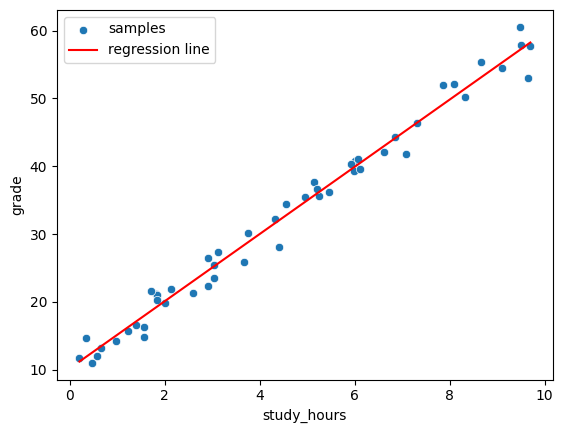

In [249]:
sns.scatterplot(data=df, x="study_hours", y="grade", label="samples")
plt.plot(x_range, y_pred, color="red", label="regression line")
plt.legend()
plt.show()

In [250]:
numpy_array = df["study_hours"].values

In [251]:
sh_tensor = torch.tensor(numpy_array)

In [252]:
sh_tensor.ndim

1

In [253]:
sh_tensor.shape

torch.Size([50])

In [254]:
# vektor ama tensor

In [255]:
x = torch.tensor(df["study_hours"].values)
y = torch.tensor(df["grade"].values)

In [256]:
x

tensor([3.7454, 9.5071, 7.3199, 5.9866, 1.5602, 1.5599, 0.5808, 8.6618, 6.0112,
        7.0807, 0.2058, 9.6991, 8.3244, 2.1234, 1.8182, 1.8340, 3.0424, 5.2476,
        4.3195, 2.9123, 6.1185, 1.3949, 2.9214, 3.6636, 4.5607, 7.8518, 1.9967,
        5.1423, 5.9241, 0.4645, 6.0754, 1.7052, 0.6505, 9.4889, 9.6563, 8.0840,
        3.0461, 0.9767, 6.8423, 4.4015, 1.2204, 4.9518, 0.3439, 9.0932, 2.5878,
        6.6252, 3.1171, 5.2007, 5.4671, 1.8485], dtype=torch.float64)

In [257]:
y

tensor([30.2039, 57.8785, 46.3684, 39.3307, 14.8439, 16.3600, 11.9829, 55.4231,
        40.7430, 41.8775, 11.6774, 57.7253, 50.2683, 21.8403, 21.1532, 21.0328,
        23.5337, 35.6194, 32.2598, 26.5125, 39.6343, 16.6034, 22.3946, 25.9257,
        34.4286, 51.9713, 19.8397, 37.7188, 40.3440, 11.0323, 41.1000, 21.6023,
        13.1809, 60.5736, 53.0421, 52.0637, 25.4048, 14.2856, 44.3952, 28.0325,
        15.6626, 35.4731, 14.6752, 54.4295, 21.3220, 42.1226, 27.4164, 36.6609,
        36.2760, 20.2693], dtype=torch.float64)

In [258]:
train_split = int(len(x)*0.8)

In [259]:
X_train, y_train = x[:train_split], y[:train_split]
X_test, y_test = x[train_split:], y[train_split:]

In [260]:
X_train

tensor([3.7454, 9.5071, 7.3199, 5.9866, 1.5602, 1.5599, 0.5808, 8.6618, 6.0112,
        7.0807, 0.2058, 9.6991, 8.3244, 2.1234, 1.8182, 1.8340, 3.0424, 5.2476,
        4.3195, 2.9123, 6.1185, 1.3949, 2.9214, 3.6636, 4.5607, 7.8518, 1.9967,
        5.1423, 5.9241, 0.4645, 6.0754, 1.7052, 0.6505, 9.4889, 9.6563, 8.0840,
        3.0461, 0.9767, 6.8423, 4.4015], dtype=torch.float64)

In [261]:
X_test

tensor([1.2204, 4.9518, 0.3439, 9.0932, 2.5878, 6.6252, 3.1171, 5.2007, 5.4671,
        1.8485], dtype=torch.float64)

In [262]:
y_train

tensor([30.2039, 57.8785, 46.3684, 39.3307, 14.8439, 16.3600, 11.9829, 55.4231,
        40.7430, 41.8775, 11.6774, 57.7253, 50.2683, 21.8403, 21.1532, 21.0328,
        23.5337, 35.6194, 32.2598, 26.5125, 39.6343, 16.6034, 22.3946, 25.9257,
        34.4286, 51.9713, 19.8397, 37.7188, 40.3440, 11.0323, 41.1000, 21.6023,
        13.1809, 60.5736, 53.0421, 52.0637, 25.4048, 14.2856, 44.3952, 28.0325],
       dtype=torch.float64)

In [263]:
y_test

tensor([15.6626, 35.4731, 14.6752, 54.4295, 21.3220, 42.1226, 27.4164, 36.6609,
        36.2760, 20.2693], dtype=torch.float64)

In [264]:
if torch.cuda.is_available:
  device = "gpu"

else:
  device = "cpu"

In [265]:
device

'gpu'

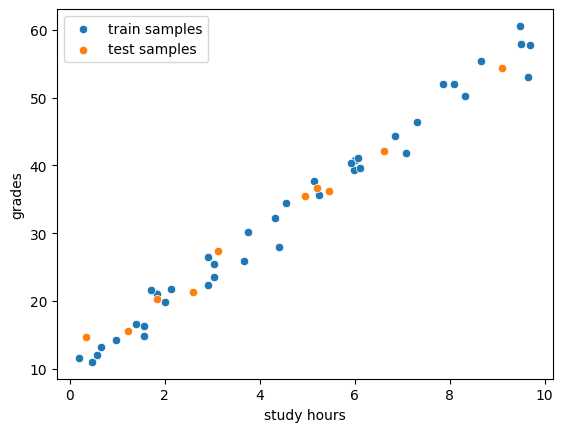

In [266]:
sns.scatterplot(x=X_train, y=y_train, label="train samples")
sns.scatterplot(x=X_test, y=y_test, label="test samples")
plt.xlabel("study hours")
plt.ylabel("grades")
plt.legend()
plt.show()

In [267]:
from torch import nn

class SimpleLinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.weights = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
    self.bias = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias




In [268]:
torch.manual_seed(42)

In [269]:
model_0 = SimpleLinearRegressionModel()
model_0 = torch.compile(model_0) # TorchDynamo ile modeli optimize ediyor.


In [270]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [271]:
model_0.state_dict()

OrderedDict([('_orig_mod.weights', tensor([0.3367])),
             ('_orig_mod.bias', tensor([0.1288]))])

In [272]:
with torch.inference_mode():
  print(model_0(X_test))

tensor([0.5397, 1.7960, 0.2446, 3.1904, 1.0001, 2.3595, 1.1783, 1.8798, 1.9695,
        0.7512], dtype=torch.float64)


In [273]:
y_test

tensor([15.6626, 35.4731, 14.6752, 54.4295, 21.3220, 42.1226, 27.4164, 36.6609,
        36.2760, 20.2693], dtype=torch.float64)

In [274]:
with torch.inference_mode():
  y_pred_first = model_0(X_test)

In [275]:
len(X_test)

10

In [276]:
len(y_pred)

100

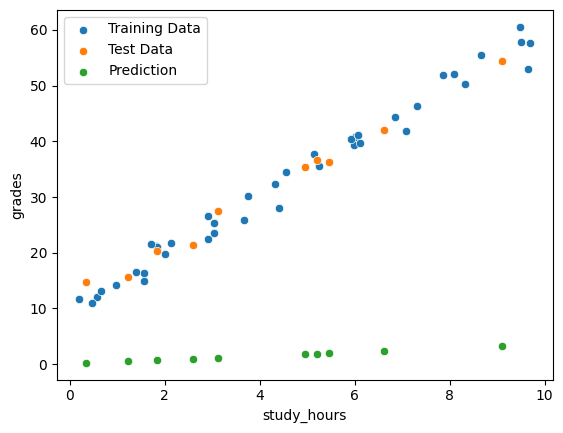

In [278]:
sns.scatterplot(x=X_train, y=y_train, label="Training Data")
sns.scatterplot(x=X_test, y=y_test, label="Test Data")
sns.scatterplot(x=X_test, y=y_pred_first, label="Prediction")
plt.xlabel("study_hours")
plt.ylabel("grades")
plt.show()

In [279]:
# model eğitilmediği için prediction çok kötü duruyor. Bizim buradaki amacımız modeli eğiterek iyileştirmeler yapmak.

In [280]:
# loss function, optimizerlar

In [281]:
 loss_fn = nn.MSELoss() # L1Loss() --> MAE

 optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.001)

In [282]:
torch.manual_seed(42)

epochs = 80
train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):

  model_0.train()
  y_pred = model_0(X_train)
  loss = loss_fn(y_pred, y_train)
  train_loss_values.append(loss.detach().numpy())

  optimizer.zero_grad() # bununla beraber alttaki üç satır backpropation için.
  loss.backward()
  optimizer.step()


  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred, y_test)
    test_loss_values.append(test_loss.detach().numpy())


  if epoch % 5 == 0:
    epoch_count.append(epoch)
    print(f"train_loss: {loss}, test_loss: {test_loss}")

train_loss: 1156.0767463081781, test_loss: 858.308860146661
train_loss: 633.9334744710083, test_loss: 484.2837829868178
train_loss: 352.99125276114285, test_loss: 280.90521005460033
train_loss: 201.80191856738534, test_loss: 169.8918797355706
train_loss: 120.41268871324436, test_loss: 108.98031233032034
train_loss: 76.57232180621143, test_loss: 75.32370882849361
train_loss: 52.931428428694815, test_loss: 56.55033419714631
train_loss: 40.157054153236494, test_loss: 45.9453113422317
train_loss: 33.22853631952331, test_loss: 39.85291566548663
train_loss: 29.44509239691046, test_loss: 36.27478245490597
train_loss: 27.353849871049174, test_loss: 34.112658291136
train_loss: 26.173215583708338, test_loss: 32.758721543163134
train_loss: 25.48277112837836, test_loss: 31.873637954658694
train_loss: 25.05632761565991, test_loss: 31.265737586178062
train_loss: 24.772208658145605, test_loss: 30.82530131461713
train_loss: 24.564967908428706, test_loss: 30.488452842580585


In [283]:
train_loss_values

[array(1156.07674631),
 array(1024.29738469),
 array(907.88321384),
 array(805.04235829),
 array(714.19187224),
 array(633.93347447),
 array(563.03187981),
 array(500.39589796),
 array(445.06159509),
 array(396.17743635),
 array(352.99125276),
 array(314.83849947),
 array(281.1322208),
 array(251.35383119),
 array(225.04528376),
 array(201.80191857),
 array(181.26631068),
 array(163.12262064),
 array(147.09195287),
 array(132.92785337),
 array(120.41268871),
 array(109.3541626),
 array(99.58234355),
 array(90.94724669),
 array(83.316253),
 array(76.57232181),
 array(70.61197222),
 array(65.34383303),
 array(60.68717301),
 array(56.57069908),
 array(52.93142843),
 array(49.71369495),
 array(46.86834245),
 array(44.35193918),
 array(42.12614215),
 array(40.15705415),
 array(38.41473399),
 array(36.87276293),
 array(35.50776247),
 array(34.29909978),
 array(33.22853632),
 array(32.27997919),
 array(31.4392147),
 array(30.69366421),
 array(30.03222876),
 array(29.4450924),
 array(28.923603

In [284]:
test_loss_values

[array(858.30886015),
 array(764.20470741),
 array(680.93392318),
 array(607.24146457),
 array(542.01819322),
 array(484.28378299),
 array(433.17181427),
 array(387.9164892),
 array(347.84090986),
 array(312.34679525),
 array(280.90521005),
 array(253.04864981),
 array(228.36375606),
 array(206.4851376),
 array(187.08971815),
 array(169.89187974),
 array(154.63899293),
 array(141.10775682),
 array(129.10063089),
 array(118.44297997),
 array(108.98031233),
 array(100.57592573),
 array(93.10900595),
 array(86.47256637),
 array(80.57204879),
 array(75.32370883),
 array(70.65347662),
 array(66.49578616),
 array(62.79262544),
 array(59.49263863),
 array(56.5503342),
 array(53.92544799),
 array(51.58231657),
 array(49.48937462),
 array(47.61863695),
 array(45.94531134),
 array(44.44745831),
 array(43.10559356),
 array(41.9024632),
 array(40.82275705),
 array(39.85291567),
 array(38.98091403),
 array(38.19605957),
 array(37.48887545),
 array(36.85093639),
 array(36.27478245),
 array(35.753778

In [285]:
len(epoch_count)

16

In [286]:
type(epoch_count)

list

In [287]:
len(train_loss_values)

80

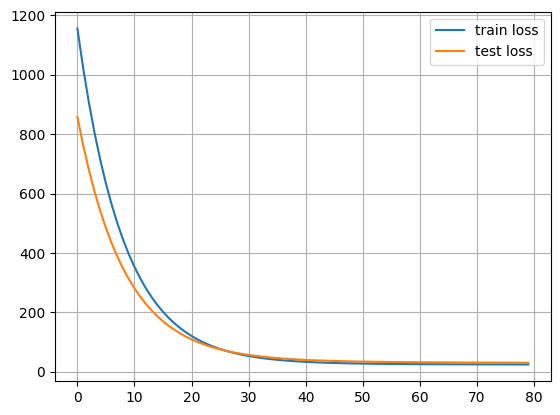

In [288]:
plt.plot(train_loss_values, label="train loss")
plt.plot(test_loss_values, label="test loss")

plt.legend()
plt.grid()
plt.show()

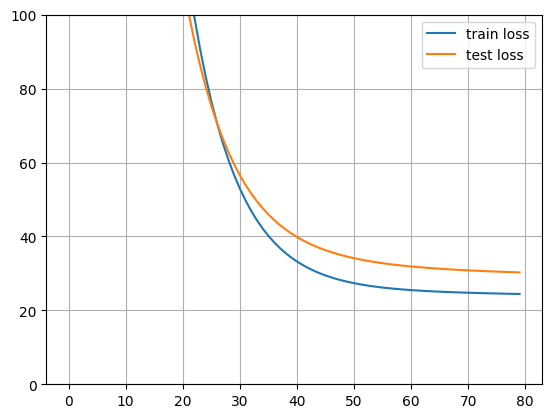

In [289]:
plt.plot(train_loss_values, label="train loss")
plt.plot(test_loss_values, label="test loss")
plt.ylim(0,100)
plt.legend()
plt.grid()
plt.show()

In [290]:
with torch.inference_mode(): # with -> context manager -> __enter__, __exit__
  y_pred_nn = model_0(X_test)

In [291]:
y_pred

tensor([25.0080, 61.2331, 47.4817, 39.0987, 11.2691, 11.2676,  5.1117, 55.9180,
        39.2531, 45.9778,  2.7541, 62.4399, 53.7971, 14.8101, 12.8916, 12.9909,
        20.5882, 34.4523, 28.6171, 19.7700, 39.9282, 10.2302, 19.8276, 24.4938,
        30.1339, 50.8254, 14.0138, 33.7908, 38.7061,  4.3803, 39.6574, 12.1811,
         5.5498, 61.1181, 62.1710, 52.2854, 20.6116,  7.6007, 44.4789, 29.1331],
       dtype=torch.float64, grad_fn=<CompiledFunctionBackward>)

In [ ]:
X_test

In [ ]:
y_pred

In [ ]:
X_train

In [ ]:
X_train

In [ ]:
y_pred

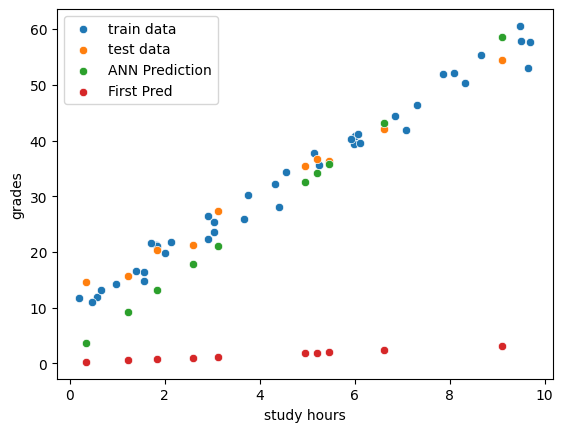

In [294]:
sns.scatterplot(x=X_train, y=y_train, label="train data")
sns.scatterplot(x=X_test, y=y_test, label="test data")
sns.scatterplot(x=X_test, y=y_pred_nn, label="ANN Prediction")
sns.scatterplot(x=X_test, y=y_pred_first, label="First Pred")


plt.xlabel("study hours")
plt.ylabel("grades")
plt.legend()
plt.show()

In [293]:
type(X_test)

torch.Tensor

In [ ]:
# ANN eğitildikten sonra gözle görülür bir fark yarattı.